In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt     
import seaborn as sns

In [3]:
transaction = pd.read_csv("../dataset/train_transaction.csv")
identity = pd.read_csv("../dataset/train_identity.csv")

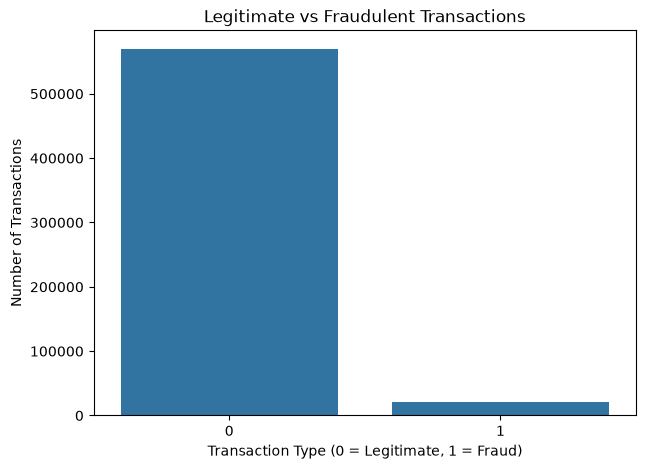

In [4]:
# Fraud distribution

fraud_counts = transaction["isFraud"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

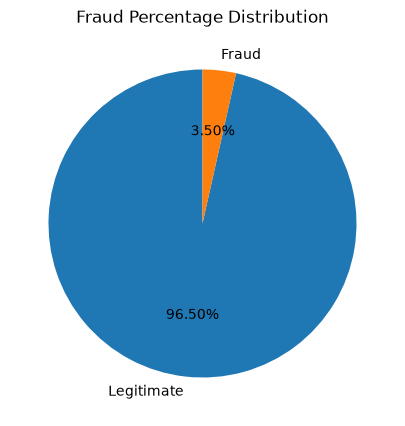

In [5]:
fraud_percentage = (
    transaction["isFraud"]
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

plt.pie(
    fraud_percentage,
    labels=["Legitimate", "Fraud"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Fraud Percentage Distribution")

plt.show()

In [6]:
print("Transaction duplicates:",
      transaction["TransactionID"].duplicated().sum())

print("Identity duplicates:",
      identity["TransactionID"].duplicated().sum())

Transaction duplicates: 0
Identity duplicates: 0


In [7]:
df = transaction.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

print("Combined dataset shape:", df.shape)

Combined dataset shape: (590540, 434)


In [8]:
missing_percentage=(df.isnull().sum()/len(df))*100
print(missing_percentage.sort_values(ascending=False).head(25))

id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
D8       87.312290
id_10    87.312290
D9       87.312290
id_30    86.865411
id_32    86.861855
dtype: float64


In [9]:
print(df.groupby("isFraud")["TransactionAmt"].describe())

            count        mean         std    min     25%   50%    75%  \
isFraud                                                                 
0        569877.0  134.511665  239.395078  0.251  43.970  68.5  120.0   
1         20663.0  149.244779  232.212163  0.292  35.044  75.0  161.0   

               max  
isFraud             
0        31937.391  
1         5191.000  


In [10]:
print(df.dtypes.value_counts())
print(df[['TransactionID','TransactionAmt','ProductCD','isFraud']].head())

float64    399
str         31
int64        4
Name: count, dtype: int64
   TransactionID  TransactionAmt ProductCD  isFraud
0        2987000            68.5         W        0
1        2987001            29.0         W        0
2        2987002            59.0         W        0
3        2987003            50.0         W        0
4        2987004            50.0         H        0


In [11]:
print(df['isFraud'].value_counts())
print('Final shape:',df.shape)

isFraud
0    569877
1     20663
Name: count, dtype: int64
Final shape: (590540, 434)


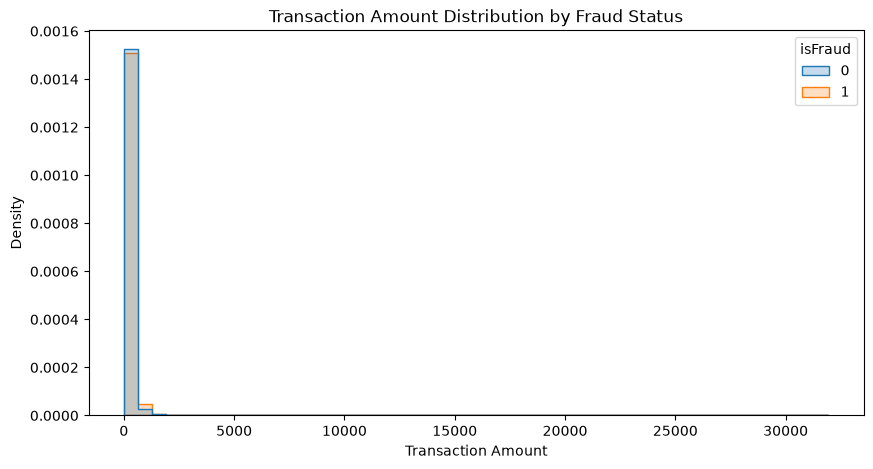

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="TransactionAmt",
    hue="isFraud",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()

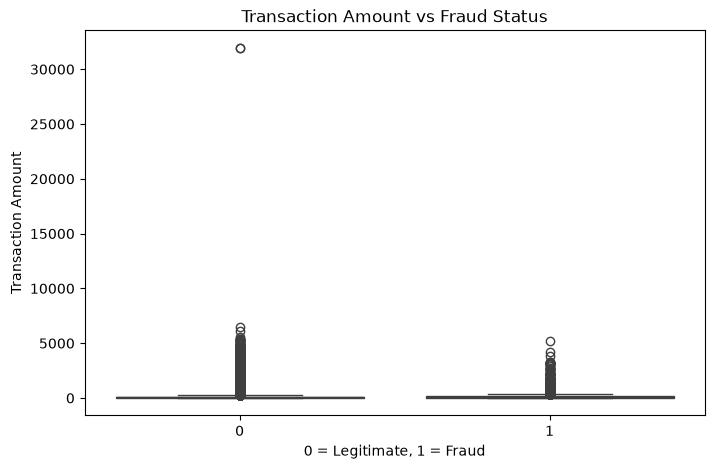

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="TransactionAmt"
)

plt.title("Transaction Amount vs Fraud Status")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Transaction Amount")

plt.show()

In [14]:
df["identity_missing"] = df["id_01"].isnull()

print(
    df.groupby("isFraud")["identity_missing"]
    .mean() * 100
)

isFraud
0    76.676546
1    45.225766
Name: identity_missing, dtype: float64


In [15]:
print(df.dtypes.value_counts())

print(
    df[[
        "TransactionID",
        "TransactionAmt",
        "ProductCD",
        "isFraud"
    ]].head()
)

float64    399
str         31
int64        4
bool         1
Name: count, dtype: int64
   TransactionID  TransactionAmt ProductCD  isFraud
0        2987000            68.5         W        0
1        2987001            29.0         W        0
2        2987002            59.0         W        0
3        2987003            50.0         W        0
4        2987004            50.0         H        0


In [16]:
print("Final dataset shape:", df.shape)
print(df["isFraud"].value_counts())

Final dataset shape: (590540, 435)
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [17]:
print("Duplicate transaction IDs:",df["TransactionID"].duplicated().sum())

Duplicate transaction IDs: 0


In [18]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [19]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

print("\nCategorical features:")
print(categorical_columns.tolist())

Numerical columns: 403
Categorical columns: 31

Categorical features:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


C:\Users\alkal\AppData\Local\Temp\ipykernel_85296\4017601000.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [20]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_report.head(30))

       Missing_Count  Missing_Percentage
id_24         585793           99.196159
id_25         585408           99.130965
id_07         585385           99.127070
id_08         585385           99.127070
id_21         585381           99.126393
id_26         585377           99.125715
id_27         585371           99.124699
id_23         585371           99.124699
id_22         585371           99.124699
dist2         552913           93.628374
D7            551623           93.409930
id_18         545427           92.360721
D13           528588           89.509263
D14           528353           89.469469
D12           525823           89.041047
id_04         524216           88.768923
id_03         524216           88.768923
D6            517353           87.606767
id_33         517251           87.589494
id_09         515614           87.312290
D8            515614           87.312290
id_10         515614           87.312290
D9            515614           87.312290
id_30         51

In [21]:
print("Dataset shape:", df.shape)

print("\nFraud distribution:")
print(df["isFraud"].value_counts())

Dataset shape: (590540, 435)

Fraud distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [22]:
missing_analysis = df.groupby("isFraud")[
    "identity_missing"
].mean() * 100

print(missing_analysis)

isFraud
0    76.676546
1    45.225766
Name: identity_missing, dtype: float64


In [23]:
print(
    df.groupby("isFraud")["TransactionAmt"]
    .median()
)

isFraud
0    68.5
1    75.0
Name: TransactionAmt, dtype: float64


In [24]:
print(df["TransactionDT"].describe())

count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64


In [25]:
print(
    df[["TransactionID", "TransactionDT", "card1"]].head(10)
)

   TransactionID  TransactionDT  card1
0        2987000          86400  13926
1        2987001          86401   2755
2        2987002          86469   4663
3        2987003          86499  18132
4        2987004          86506   4497
5        2987005          86510   5937
6        2987006          86522  12308
7        2987007          86529  12695
8        2987008          86535   2803
9        2987009          86536  17399


In [26]:
df_sorted = df.sort_values(
    ["TransactionDT", "TransactionID"]
).reset_index(drop=True).copy()

df_sorted["event_time"] = pd.to_timedelta(
    df_sorted["TransactionDT"],
    unit="s"
)

In [27]:
def calculate_velocity(group):

    group = group.sort_values("event_time").copy()

    group["transaction_count_1h"] = (
        group.rolling(
            "1h",
            on="event_time",
            closed="left"
        )["TransactionID"]
        .count()
        .to_numpy()
    )

    return group


df_sorted = (
    df_sorted.groupby("card1", dropna=False, group_keys=False)
    .apply(calculate_velocity, include_groups=False)
    .reset_index(drop=True)
)

In [28]:
df_sorted = df.sort_values(
    ["TransactionDT", "TransactionID"]
).reset_index(drop=True).copy()

df_sorted["event_time"] = pd.to_timedelta(
    df_sorted["TransactionDT"],
    unit="s"
)

df_sorted["transaction_count_1h"] = 0.0

for card, group in df_sorted.groupby("card1", dropna=False, sort=False):

    counts = (
        group.rolling(
            "1h",
            on="event_time",
            closed="left"
        )["TransactionID"]
        .count()
    )

    df_sorted.loc[group.index, "transaction_count_1h"] = counts.to_numpy()

In [29]:
print(
    df_sorted[
        [
            "TransactionID",
            "TransactionDT",
            "card1",
            "transaction_count_1h"
        ]
    ].head(20)
)

    TransactionID  TransactionDT  card1  transaction_count_1h
0         2987000          86400  13926                   NaN
1         2987001          86401   2755                   NaN
2         2987002          86469   4663                   NaN
3         2987003          86499  18132                   NaN
4         2987004          86506   4497                   NaN
5         2987005          86510   5937                   NaN
6         2987006          86522  12308                   NaN
7         2987007          86529  12695                   NaN
8         2987008          86535   2803                   NaN
9         2987009          86536  17399                   NaN
10        2987010          86549  16496                   NaN
11        2987011          86555   4461                   NaN
12        2987012          86564   3786                   NaN
13        2987013          86585  12866                   NaN
14        2987014          86596  11839                   NaN
15      

In [30]:
print(df_sorted["transaction_count_1h"].describe())

count    247243.000000
mean          3.475508
std           8.074786
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max         191.000000
Name: transaction_count_1h, dtype: float64


In [31]:
df_sorted = df.sort_values(
    ["TransactionDT", "TransactionID"]
).reset_index(drop=True).copy()

df_sorted["event_time"] = pd.to_timedelta(
    df_sorted["TransactionDT"],
    unit="s"
)

# Unknown card identifiers remain NaN
df_sorted["transaction_count_1h"] = np.nan

# Calculate velocity only for known card identifiers
for card, group in df_sorted[
    df_sorted["card1"].notna()
].groupby("card1", sort=False):

    counts = (
        group.rolling(
            "1h",
            on="event_time",
            closed="left"
        )["TransactionID"]
        .count()
        .fillna(0)
    )

    df_sorted.loc[
        group.index,
        "transaction_count_1h"
    ] = counts.to_numpy()

In [32]:
print(df_sorted["transaction_count_1h"].describe())

print(
    "Total transactions:",
    len(df_sorted)
)

print(
    "Available velocity values:",
    df_sorted["transaction_count_1h"].count()
)

print(
    "Missing card identifiers:",
    df_sorted["card1"].isnull().sum()
)

count    590540.000000
mean          1.455100
std           5.498928
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max         191.000000
Name: transaction_count_1h, dtype: float64
Total transactions: 590540
Available velocity values: 590540
Missing card identifiers: 0


In [33]:
df_sorted["previous_avg_amount"] = np.nan

for card, group in df_sorted[
    df_sorted["card1"].notna()
].groupby("card1", sort=False):

    previous_average = (
        group["TransactionAmt"]
        .shift(1)
        .expanding()
        .mean()
    )

    df_sorted.loc[
        group.index,
        "previous_avg_amount"
    ] = previous_average.to_numpy()

In [34]:
df_sorted["transaction_amount_deviation"] = (
    df_sorted["TransactionAmt"]
    - df_sorted["previous_avg_amount"]
)

In [35]:
print(
    df_sorted[
        [
            "card1",
            "TransactionAmt",
            "previous_avg_amount",
            "transaction_amount_deviation"
        ]
    ].head(20)
)

    card1  TransactionAmt  previous_avg_amount  transaction_amount_deviation
0   13926          68.500                  NaN                           NaN
1    2755          29.000                  NaN                           NaN
2    4663          59.000                  NaN                           NaN
3   18132          50.000                  NaN                           NaN
4    4497          50.000                  NaN                           NaN
5    5937          49.000                  NaN                           NaN
6   12308         159.000                  NaN                           NaN
7   12695         422.500                  NaN                           NaN
8    2803          15.000                  NaN                           NaN
9   17399         117.000                  NaN                           NaN
10  16496          75.887                  NaN                           NaN
11   4461          16.495                  NaN                           NaN

In [36]:
print(
    df_sorted[
        [
            "previous_avg_amount",
            "transaction_amount_deviation"
        ]
    ].describe()
)

       previous_avg_amount  transaction_amount_deviation
count        576987.000000                 576987.000000
mean            128.879068                      5.925100
std              79.615775                    232.237596
min               0.615000                  -4019.970000
25%              91.950299                    -72.729813
50%             115.772211                    -31.049286
75%             148.326458                     15.011526
max            4517.710000                  31718.559014


In [37]:
print(
    df_sorted.groupby("isFraud")[
        "transaction_amount_deviation"
    ].median()
)

isFraud
0   -31.925501
1   -13.488715
Name: transaction_amount_deviation, dtype: float64


In [38]:


df_sorted["transaction_count_24h"] = np.nan

for card, group in df_sorted[
    df_sorted["card1"].notna()
].groupby("card1", sort=False):

    counts = (
        group.rolling(
            window="24h",
            on="event_time",
            closed="left"
        )["TransactionID"]
        .count()
        .fillna(0)
    )

    df_sorted.loc[
        group.index,
        "transaction_count_24h"
    ] = counts.to_numpy()


In [39]:
print(
    df_sorted[
        [
            "transaction_count_1h",
            "transaction_count_24h"
        ]
    ].describe()
)

       transaction_count_1h  transaction_count_24h
count         590540.000000          590540.000000
mean               1.455100              18.803534
std                5.498928              45.610706
min                0.000000               0.000000
25%                0.000000               1.000000
50%                0.000000               5.000000
75%                1.000000              19.000000
max              191.000000             880.000000


In [40]:
print(df_sorted["transaction_count_24h"].describe())

count    590540.000000
mean         18.803534
std          45.610706
min           0.000000
25%           1.000000
50%           5.000000
75%          19.000000
max         880.000000
Name: transaction_count_24h, dtype: float64


In [41]:
print(df_sorted[
    ["transaction_count_1h","transaction_count_24h"]
].describe())

       transaction_count_1h  transaction_count_24h
count         590540.000000          590540.000000
mean               1.455100              18.803534
std                5.498928              45.610706
min                0.000000               0.000000
25%                0.000000               1.000000
50%                0.000000               5.000000
75%                1.000000              19.000000
max              191.000000             880.000000


In [42]:
velocity_comparison=df_sorted.groupby("isFraud")[
    ["transaction_count_1h","transaction_count_24h"]
].agg(["mean","median","max"])

print(velocity_comparison)

        transaction_count_1h               transaction_count_24h              
                        mean median    max                  mean median    max
isFraud                                                                       
0                   1.460089    0.0  191.0             18.931180    5.0  880.0
1                   1.317524    1.0   45.0             15.283115    6.0  475.0


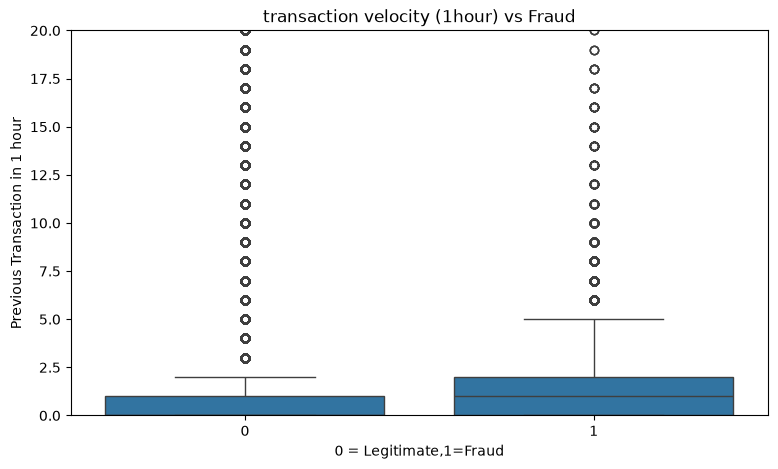

In [43]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df_sorted,
    x="isFraud",
    y="transaction_count_1h"
)

plt.title("transaction velocity (1hour) vs Fraud")
plt.xlabel("0 = Legitimate,1=Fraud")
plt.ylabel("Previous Transaction in 1 hour")

plt.ylim(0,20)
plt.show()

In [44]:
print(df["DeviceType"].value_counts(dropna=False))

DeviceType
NaN        449730
desktop     85165
mobile      55645
Name: count, dtype: int64


In [45]:
device_fraud=pd.crosstab(
    df["DeviceType"],
    df["isFraud"],
    normalize="index"
)*100

print(device_fraud)

isFraud             0          1
DeviceType                      
desktop     93.478542   6.521458
mobile      89.833768  10.166232


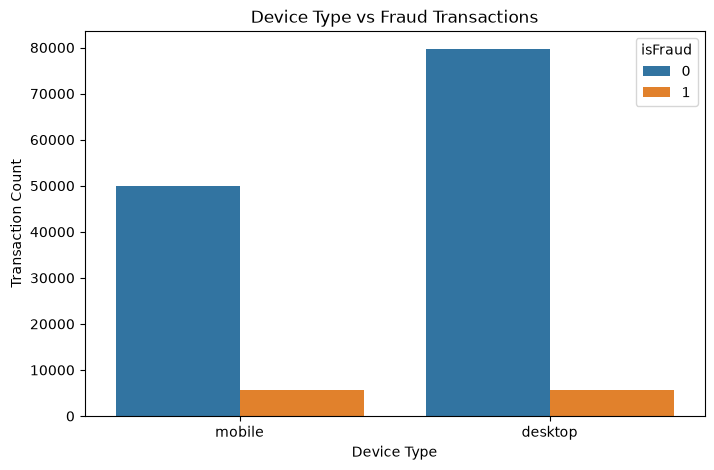

In [46]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="DeviceType",
    hue="isFraud"
)

plt.title("Device Type vs Fraud Transactions")
plt.xlabel("Device Type")
plt.ylabel("Transaction Count")

plt.show()

In [47]:
print(df["id_30"].value_counts().head(15))

id_30
Windows 10          21155
Windows 7           13110
iOS 11.2.1           3722
iOS 11.1.2           3699
Android 7.0          2871
Mac OS X 10_12_6     2559
Mac OS X 10_11_6     2348
iOS 11.3.0           2016
Windows 8.1          1914
Mac OS X 10_10_5     1651
iOS 11.2.6           1647
iOS 10.3.3           1558
Mac OS X 10_13_2     1421
Mac OS X 10_13_1     1211
iOS 11.2.5           1200
Name: count, dtype: int64


In [48]:
print(df["id_31"].value_counts().head(15))

id_31
chrome 63.0                22000
mobile safari 11.0         13423
mobile safari generic      11474
ie 11.0 for desktop         9030
safari generic              8195
chrome 62.0                 7182
chrome 65.0                 6871
chrome 64.0                 6711
chrome 63.0 for android     5806
chrome generic              4778
chrome 66.0                 4264
edge 16.0                   4188
chrome 64.0 for android     3473
chrome 65.0 for android     3336
firefox 57.0                3315
Name: count, dtype: int64


In [49]:
os_fraud=pd.crosstab(
    df["id_30"],
    df["isFraud"],
    normalize="index"
)*100

print(os_fraud.sort_values(1,ascending=False).head(15))

isFraud                   0          1
id_30                                 
other             40.000000  60.000000
Android 5.1.1     71.142857  28.857143
Android 4.4.2     74.603175  25.396825
iOS 11.4.0        80.000000  20.000000
iOS 11.0.1        80.314961  19.685039
iOS 11.1.0        82.287823  17.712177
iOS 11.2.5        87.833333  12.166667
Android 7.1.2     87.878788  12.121212
iOS 11.2.2        88.248337  11.751663
Windows 8         88.333333  11.666667
Mac OS X 10_12_1  88.636364  11.363636
Android 7.1.1     89.365079  10.634921
Android           89.434662  10.565338
Windows Vista     90.650407   9.349593
iOS 11.0.0        90.972222   9.027778


In [50]:
print(df["id_30"].value_counts().head(15))

id_30
Windows 10          21155
Windows 7           13110
iOS 11.2.1           3722
iOS 11.1.2           3699
Android 7.0          2871
Mac OS X 10_12_6     2559
Mac OS X 10_11_6     2348
iOS 11.3.0           2016
Windows 8.1          1914
Mac OS X 10_10_5     1651
iOS 11.2.6           1647
iOS 10.3.3           1558
Mac OS X 10_13_2     1421
Mac OS X 10_13_1     1211
iOS 11.2.5           1200
Name: count, dtype: int64


In [51]:
print(df["id_31"].value_counts().head(15))

id_31
chrome 63.0                22000
mobile safari 11.0         13423
mobile safari generic      11474
ie 11.0 for desktop         9030
safari generic              8195
chrome 62.0                 7182
chrome 65.0                 6871
chrome 64.0                 6711
chrome 63.0 for android     5806
chrome generic              4778
chrome 66.0                 4264
edge 16.0                   4188
chrome 64.0 for android     3473
chrome 65.0 for android     3336
firefox 57.0                3315
Name: count, dtype: int64


In [52]:
os_analysis = df.groupby("id_30").agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

os_analysis["fraud_rate"] = (
    os_analysis["fraud_rate"] * 100
)

os_analysis = os_analysis[
    os_analysis["total_transactions"] >= 100
]

print(
    os_analysis.sort_values(
        "fraud_rate",
        ascending=False
    ).head(15)
)

               total_transactions  fraud_transactions  fraud_rate
id_30                                                            
Android 5.1.1                 350                 101   28.857143
iOS 11.0.1                    127                  25   19.685039
iOS 11.1.0                    271                  48   17.712177
iOS 11.2.5                   1200                 146   12.166667
iOS 11.2.2                    902                 106   11.751663
Windows 8                     180                  21   11.666667
Android 7.1.1                 630                  67   10.634921
Android                      1079                 114   10.565338
Windows Vista                 246                  23    9.349593
iOS 11.0.0                    144                  13    9.027778
iOS 10.2.1                    285                  25    8.771930
Android 6.0.1                 566                  48    8.480565
iOS 11.2.0                    852                  72    8.450704
iOS 10.2.0

In [53]:
browser_analysis = df.groupby("id_31").agg(
    total_transactions=("isFraud", "count"),
    fraud_transactions=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

browser_analysis["fraud_rate"] *= 100

browser_analysis = browser_analysis[
    browser_analysis["total_transactions"] >= 100
]

print(
    browser_analysis.sort_values(
        "fraud_rate",
        ascending=False
    ).head(15)
)

                         total_transactions  fraud_transactions  fraud_rate
id_31                                                                      
chrome 52.0 for android                 152                  58   38.157895
opera 49.0                              138                  43   31.159420
chrome 58.0                             188                  51   27.127660
chrome 50.0 for android                 145                  38   26.206897
android webview 4.0                     285                  69   24.210526
firefox                                 673                 147   21.842496
other                                   312                  61   19.551282
chrome 58.0 for android                 262                  50   19.083969
chrome 56.0 for android                 238                  44   18.487395
chrome generic                         4778                 803   16.806195
chrome 64.0 for android                3473                 552   15.894040
android brow

In [54]:
print(
    os_analysis.sort_values(
        "fraud_rate",
        ascending=False
    ).head(15)
)

               total_transactions  fraud_transactions  fraud_rate
id_30                                                            
Android 5.1.1                 350                 101   28.857143
iOS 11.0.1                    127                  25   19.685039
iOS 11.1.0                    271                  48   17.712177
iOS 11.2.5                   1200                 146   12.166667
iOS 11.2.2                    902                 106   11.751663
Windows 8                     180                  21   11.666667
Android 7.1.1                 630                  67   10.634921
Android                      1079                 114   10.565338
Windows Vista                 246                  23    9.349593
iOS 11.0.0                    144                  13    9.027778
iOS 10.2.1                    285                  25    8.771930
Android 6.0.1                 566                  48    8.480565
iOS 11.2.0                    852                  72    8.450704
iOS 10.2.0

In [55]:
print("Missing card1 values:", df_sorted["card1"].isna().sum())

print("\nMissing velocity values:")
print(df_sorted[
    ["transaction_count_1h", "transaction_count_24h"]
].isna().sum())

Missing card1 values: 0

Missing velocity values:
transaction_count_1h     0
transaction_count_24h    0
dtype: int64


In [56]:
print("Original df missing card1:",
      df["card1"].isna().sum())

print("Sorted df missing card1:",
      df_sorted["card1"].isna().sum())

print("Unique card1 values:",
      df_sorted["card1"].nunique())

Original df missing card1: 0
Sorted df missing card1: 0
Unique card1 values: 13553


In [57]:
print(df_sorted[
    ["card1", "TransactionDT",
     "transaction_count_1h",
     "transaction_count_24h"]
].head(10))

   card1  TransactionDT  transaction_count_1h  transaction_count_24h
0  13926          86400                   0.0                    0.0
1   2755          86401                   0.0                    0.0
2   4663          86469                   0.0                    0.0
3  18132          86499                   0.0                    0.0
4   4497          86506                   0.0                    0.0
5   5937          86510                   0.0                    0.0
6  12308          86522                   0.0                    0.0
7  12695          86529                   0.0                    0.0
8   2803          86535                   0.0                    0.0
9  17399          86536                   0.0                    0.0


In [58]:
sample_card = df_sorted["card1"].value_counts().index[0]

sample = df_sorted[
    df_sorted["card1"] == sample_card
][[
    "card1",
    "TransactionDT",
    "transaction_count_1h",
    "transaction_count_24h"
]]

print(sample.head(10))

     card1  TransactionDT  transaction_count_1h  transaction_count_24h
526   7919          95442                   0.0                    0.0
843   7919         105504                   0.0                    1.0
882   7919         107187                   1.0                    2.0
906   7919         108490                   2.0                    3.0
913   7919         108692                   3.0                    4.0
914   7919         108712                   4.0                    5.0
918   7919         108789                   5.0                    6.0
920   7919         108821                   6.0                    7.0
921   7919         108836                   7.0                    8.0
922   7919         108862                   8.0                    9.0


In [59]:
print("Dataset shape:", df_sorted.shape)

print("\nTarget distribution:")
print(df_sorted["isFraud"].value_counts())

print("\nTarget percentages:")
print(df_sorted["isFraud"].value_counts(normalize=True) * 100)

Dataset shape: (590540, 440)

Target distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Target percentages:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


In [60]:
print("Minimum TransactionDT:",
      df_sorted["TransactionDT"].min())

print("Maximum TransactionDT:",
      df_sorted["TransactionDT"].max())

print("Unique TransactionDT values:",
      df_sorted["TransactionDT"].nunique())

Minimum TransactionDT: 86400
Maximum TransactionDT: 15811131
Unique TransactionDT values: 573349


In [61]:
split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index].copy()
val_df = df_sorted.iloc[split_index:].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nTraining time range:")
print(train_df["TransactionDT"].min(),
      train_df["TransactionDT"].max())

print("\nValidation time range:")
print(val_df["TransactionDT"].min(),
      val_df["TransactionDT"].max())

Training shape: (472432, 440)
Validation shape: (118108, 440)

Training time range:
86400 12192842

Validation time range:
12192900 15811131


In [62]:
print("Training fraud distribution:")
print(train_df["isFraud"].value_counts(normalize=True) * 100)

print("\nValidation fraud distribution:")
print(val_df["isFraud"].value_counts(normalize=True) * 100)

Training fraud distribution:
isFraud
0    96.486478
1     3.513522
Name: proportion, dtype: float64

Validation fraud distribution:
isFraud
0    96.559082
1     3.440918
Name: proportion, dtype: float64


In [63]:
print("Training last timestamp:",
      train_df["TransactionDT"].max())

print("Validation first timestamp:",
      val_df["TransactionDT"].min())

print("Chronological split valid:",
      train_df["TransactionDT"].max()
      <= val_df["TransactionDT"].min())

Training last timestamp: 12192842
Validation first timestamp: 12192900
Chronological split valid: True


In [64]:
historical_features = [
    "transaction_count_1h",
    "transaction_count_24h",
    "previous_avg_amount",
    "transaction_amount_deviation"
]

print(df_sorted[historical_features].describe())


       transaction_count_1h  transaction_count_24h  previous_avg_amount  \
count         590540.000000          590540.000000        576987.000000   
mean               1.455100              18.803534           128.879068   
std                5.498928              45.610706            79.615775   
min                0.000000               0.000000             0.615000   
25%                0.000000               1.000000            91.950299   
50%                0.000000               5.000000           115.772211   
75%                1.000000              19.000000           148.326458   
max              191.000000             880.000000          4517.710000   

       transaction_amount_deviation  
count                 576987.000000  
mean                       5.925100  
std                      232.237596  
min                    -4019.970000  
25%                      -72.729813  
50%                      -31.049286  
75%                       15.011526  
max                 

In [65]:
print(
    df_sorted[historical_features].isna().sum()
)

transaction_count_1h                0
transaction_count_24h               0
previous_avg_amount             13553
transaction_amount_deviation    13553
dtype: int64


In [66]:
missing_history = df_sorted[
    df_sorted["previous_avg_amount"].isna()
]

print(missing_history[
    ["card1", "TransactionDT", "TransactionAmt",
     "previous_avg_amount",
     "transaction_amount_deviation"]
].head(10))

   card1  TransactionDT  TransactionAmt  previous_avg_amount  \
0  13926          86400            68.5                  NaN   
1   2755          86401            29.0                  NaN   
2   4663          86469            59.0                  NaN   
3  18132          86499            50.0                  NaN   
4   4497          86506            50.0                  NaN   
5   5937          86510            49.0                  NaN   
6  12308          86522           159.0                  NaN   
7  12695          86529           422.5                  NaN   
8   2803          86535            15.0                  NaN   
9  17399          86536           117.0                  NaN   

   transaction_amount_deviation  
0                           NaN  
1                           NaN  
2                           NaN  
3                           NaN  
4                           NaN  
5                           NaN  
6                           NaN  
7                      

In [67]:
print("Missing history rows:",
      len(missing_history))

print("Unique card1 values in missing rows:",
      missing_history["card1"].nunique())

Missing history rows: 13553
Unique card1 values in missing rows: 13553


In [68]:
df_sorted["has_previous_history"] = (
    df_sorted["previous_avg_amount"].notna().astype(int)
)

print(df_sorted["has_previous_history"].value_counts())

has_previous_history
1    576987
0     13553
Name: count, dtype: int64


In [69]:
categorical_columns = df_sorted.select_dtypes(
    include=["object", "category", "str"]
).columns

print("Number of categorical columns:",
      len(categorical_columns))

print("\nFirst 15 categorical columns:")
print(categorical_columns[:15])

Number of categorical columns: 31

First 15 categorical columns:
Index(['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1',
       'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12'],
      dtype='str')


In [70]:
for col in categorical_columns[:5]:
    print(f"\n{col}")
    print(df_sorted[col].value_counts().head(5))


ProductCD
ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64

card4
card4
visa                384767
mastercard          189217
american express      8328
discover              6651
Name: count, dtype: int64

card6
card6
debit              439938
credit             148986
debit or credit        30
charge card            15
Name: count, dtype: int64

P_emaildomain
P_emaildomain
gmail.com        228355
yahoo.com        100934
hotmail.com       45250
anonymous.com     36998
aol.com           28289
Name: count, dtype: int64

R_emaildomain
R_emaildomain
gmail.com        57147
hotmail.com      27509
anonymous.com    20529
yahoo.com        11842
aol.com           3701
Name: count, dtype: int64


In [71]:
for col in categorical_columns[:10]:
    print(
        col,
        "→",
        df_sorted[col].nunique(),
        "unique categories"
    )

ProductCD → 5 unique categories
card4 → 4 unique categories
card6 → 4 unique categories
P_emaildomain → 59 unique categories
R_emaildomain → 60 unique categories
M1 → 2 unique categories
M2 → 2 unique categories
M3 → 2 unique categories
M4 → 3 unique categories
M5 → 2 unique categories


In [72]:
for col in categorical_columns[10:]:
    print(
        col,
        "→",
        df_sorted[col].nunique(),
        "unique categories"
    )

M6 → 2 unique categories
M7 → 2 unique categories
M8 → 2 unique categories
M9 → 2 unique categories
id_12 → 2 unique categories
id_15 → 3 unique categories
id_16 → 2 unique categories
id_23 → 3 unique categories
id_27 → 2 unique categories
id_28 → 2 unique categories
id_29 → 2 unique categories
id_30 → 75 unique categories
id_31 → 130 unique categories
id_33 → 260 unique categories
id_34 → 4 unique categories
id_35 → 2 unique categories
id_36 → 2 unique categories
id_37 → 2 unique categories
id_38 → 2 unique categories
DeviceType → 2 unique categories
DeviceInfo → 1786 unique categories


In [73]:
print(
    df_sorted["DeviceInfo"]
    .value_counts(dropna=False)
    .head(15)
)

DeviceInfo
NaN                            471874
Windows                         47722
iOS Device                      19782
MacOS                           12573
Trident/7.0                      7440
rv:11.0                          1901
rv:57.0                           962
SM-J700M Build/MMB29K             549
SM-G610M Build/MMB29K             461
SM-G531H Build/LMY48B             410
rv:59.0                           362
SM-G935F Build/NRD90M             334
SM-G955U Build/NRD90M             328
SM-G532M Build/MMB29T             316
ALE-L23 Build/HuaweiALE-L23       312
Name: count, dtype: int64


In [74]:
df_sorted["DeviceInfo_missing"] = (
    df_sorted["DeviceInfo"].isna().astype(int)
)

device_missing_analysis = df_sorted.groupby(
    "DeviceInfo_missing"
)["isFraud"].agg(
    total_transactions="count",
    fraud_transactions="sum",
    fraud_rate="mean"
)

device_missing_analysis["fraud_rate"] *= 100

print(device_missing_analysis)

                    total_transactions  fraud_transactions  fraud_rate
DeviceInfo_missing                                                    
0                               118666                8607    7.253131
1                               471874               12056    2.554919


In [75]:
import numpy as np
import pandas as pd

# Target
y = df_sorted["isFraud"]

# Remove target and non-feature columns
X = df_sorted.drop(
    columns=["isFraud", "TransactionID", "event_time"],
    errors="ignore"
)

# Chronological split
split_index = int(len(df_sorted) * 0.8)

X_train = X.iloc[:split_index].copy()
X_val = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_val = y.iloc[split_index:].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training fraud cases:", y_train.sum())
print("Validation fraud cases:", y_val.sum())

Training features: (472432, 439)
Validation features: (118108, 439)
Training fraud cases: 16599
Validation fraud cases: 4064


In [76]:
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 408
Categorical features: 31


In [81]:
import sys

!{sys.executable} -m pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 630.5 kB/s eta 0:00:58
    --------------------------------------- 0.8/36.6 MB 697.4 kB/s eta 0:00:52
   - -------------------------------------- 1.0/36.6 MB 805.1 kB/s eta 0:00:45
   - -------------------------------------- 1.3/36.6 MB 886.3 kB/s eta 0:00:40
   - -------------------------------------- 1.3/36.6 MB 886.3 kB/s eta 0:00:40
   - -------------------------------------- 1.3/36.6 MB


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [82]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [86]:
import sys

!{sys.executable} -m pip install scikit-learn

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 931.6 kB/s eta 0:00:09
   --- ------------------------------------ 0.8/8.2 MB 1.2 MB/s eta 0:00:07
   ----- ---------------------------------- 1.0/8.2 MB 1.3 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.2 MB 1.5 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.2 MB 1.5 MB/s eta 0:00:05
   ----------- ---------------------------- 2.4/8.2 MB 1.6 MB/s eta 0:00:04
   -------------- ------------------------- 2.9/8.2 MB 1.7 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.2 MB 1.7 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.2 MB 1.7 MB/s eta 0:00:03
   --------------- --------------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [94]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [1]:
import sklearn

print("Scikit-learn:", sklearn.__version__)

import xgboost

print("XGBoost:", xgboost.__version__)

from xgboost import XGBClassifier

print("XGBClassifier is ready!")

Scikit-learn: 1.9.1
XGBoost: 3.4.1
XGBClassifier is ready!


In [4]:
import pandas as pd
import numpy as np

transaction = pd.read_csv("../dataset/train_transaction.csv")
identity = pd.read_csv("../dataset/train_identity.csv")

df = transaction.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", df.shape)

Dataset shape: (590540, 434)


In [5]:
df_sorted = df.sort_values(
    ["TransactionDT", "TransactionID"]
).reset_index(drop=True).copy()

df_sorted["event_time"] = pd.to_timedelta(
    df_sorted["TransactionDT"], unit="s"
)

print("Sorted dataset:", df_sorted.shape)

Sorted dataset: (590540, 435)


In [6]:
# Recreate training and validation split
split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index].copy()
val_df = df_sorted.iloc[split_index:].copy()

# Separate features and target
X = df_sorted.drop(
    columns=["isFraud", "TransactionID", "event_time"],
    errors="ignore"
)

y = df_sorted["isFraud"]

X_train = X.iloc[:split_index].copy()
X_val = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_val = y.iloc[split_index:].copy()

print(X_train.shape, X_val.shape)
print(y_train.shape, y_val.shape)

(472432, 432) (118108, 432)
(472432,) (118108,)


In [7]:
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

print("Model configured successfully!")

Model configured successfully!


In [13]:
# Separate input features and target
X = df_sorted.drop(
    columns=["isFraud", "TransactionID", "event_time"],
    errors="ignore"
)

y = df_sorted["isFraud"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 401
Categorical features: 31


In [14]:
split_index = int(len(df_sorted) * 0.8)

X_train = X.iloc[:split_index].copy()
X_val = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_val = y.iloc[split_index:].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (472432, 432)
Validation: (118108, 432)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [16]:
fraud_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

print("Pipeline ready!")

Pipeline ready!


In [18]:
fraud_pipeline.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [19]:
y_pred = fraud_pipeline.predict(X_val)
y_proba = fraud_pipeline.predict_proba(X_val)[:, 1]

print("Predictions completed!")
print("Total validation predictions:", len(y_pred))

Predictions completed!
Total validation predictions: 118108


In [20]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

print("CLASSIFICATION REPORT")
print(classification_report(y_val, y_pred))

print("CONFUSION MATRIX")
print(confusion_matrix(y_val, y_pred))

print("PR-AUC:", average_precision_score(y_val, y_proba))

print("ROC-AUC:", roc_auc_score(y_val, y_proba))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.91      0.95    114044
           1       0.22      0.73      0.34      4064

    accuracy                           0.90    118108
   macro avg       0.61      0.82      0.64    118108
weighted avg       0.96      0.90      0.93    118108

CONFUSION MATRIX
[[103586  10458]
 [  1089   2975]]
PR-AUC: 0.5188656247105075
ROC-AUC: 0.9086234126688775


In [21]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

precision, recall, thresholds = precision_recall_curve(
    y_val, y_proba
)

results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

# Show thresholds with at least 80% recall
filtered = results[results["recall"] >= 0.80]

print(
    filtered.sort_values(
        "precision", ascending=False
    ).head(10)
)

       threshold  precision    recall
96970   0.400880   0.169560  0.800197
96969   0.400845   0.169552  0.800197
96968   0.400782   0.169543  0.800197
96967   0.400761   0.169534  0.800197
96966   0.400745   0.169525  0.800197
96965   0.400732   0.169516  0.800197
96959   0.400683   0.169515  0.800443
96964   0.400712   0.169507  0.800197
96958   0.400667   0.169507  0.800443
96963   0.400704   0.169499  0.800197


In [22]:
import joblib

joblib.dump(fraud_pipeline, "fraud_detection_xgboost.pkl")

print("Model saved successfully!")

Model saved successfully!


In [23]:
joblib.dump(0.5, "fraud_threshold.pkl")

['fraud_threshold.pkl']

In [24]:
feature_names = (
    fraud_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    fraud_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

print(
    feature_importance
    .sort_values("importance", ascending=False)
    .head(20)
)

                                     feature  importance
296                                num__V258    0.095470
302                                num__V264    0.060008
108                                 num__V70    0.046075
129                                 num__V91    0.033312
332                                num__V294    0.031108
239                                num__V201    0.018772
17                                   num__C8    0.018461
333                                num__V295    0.013990
225                                num__V187    0.012087
346                                num__V308    0.011713
23                                  num__C14    0.010374
405                         cat__ProductCD_W    0.009029
13                                   num__C4    0.008054
401                         cat__ProductCD_C    0.007893
410                        cat__card6_credit    0.007298
1042  cat__DeviceInfo_hi6210sft Build/MRA58K    0.005347
411                         cat

In [25]:
feature_importance.sort_values(
    "importance",
    ascending=False
).to_csv("feature_importance.csv", index=False)

print("Feature importance saved!")

Feature importance saved!


In [27]:
import sys

!{sys.executable} -m pip install torch

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 1.7 MB/s eta 0:01:13
   ---------------------------------------- 0.8/126.7 MB 1.7 MB/s eta 0:01:15
   ---------------------------------------- 1.3/126.7 MB 1.7 MB/s eta 0:01:15
   ---------------------------------------- 1.6/126.7 MB 1.6 MB/s eta 0:01:18
   ---------------------------------------- 1.6/126.7 MB 1.6 MB/s eta 0:01:18
    --------------------------------------- 1.8/126.7 MB 1.5 MB/s eta 0:01:26
    --------------------------------------- 2.1/126.7 MB 1.3 MB/s eta 0:01:35
    --------------------------------------- 2.6/126.7 MB 1.4 MB/s eta 0:01:29
    --------------------------------------- 2.


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
CUDA available: False


In [2]:
import sys

!{sys.executable} -m pip install torch-geometric

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.3 MB 736.7 kB/s eta 0:00:02
   --------------- ------------------------ 0.5/1.3 MB 736.7 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.3 MB 689.3 kB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.3 MB 689.3 kB/s eta 0:00:01
   ------------------------------- -------- 1.0/1.3 MB 720.4 kB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 785.5 kB/s  0:00:01
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)

   -- -------------------------------------  1/16 [urllib3]
   -- ---------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import torch_geometric

print("PyTorch Geometric:", torch_geometric.__version__)

c:\Users\alkal\OneDrive\Pictures\Desktop\Real-Time-Fraud-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\alkal\OneDrive\Pictures\Desktop\Real-Time-Fraud-Detection\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch Geometric: 2.8.1


In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
CUDA available: False


In [8]:
import pandas as pd
import numpy as np

transaction = pd.read_csv("../dataset/train_transaction.csv")
identity = pd.read_csv("../dataset/train_identity.csv")

df = transaction.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

df_sorted = df.sort_values(
    ["TransactionDT", "TransactionID"]
).reset_index(drop=True).copy()

print("Dataset:", df_sorted.shape)

Dataset: (590540, 434)


In [9]:
graph_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt",
    "card1", "addr1", "addr2", "C1", "C2",
    "D1", "D2", "V258", "V264", "isFraud"
]

print(df_sorted[graph_columns].head())

print("\nMissing values:")
print(df_sorted[graph_columns].isna().sum())

   TransactionID  TransactionDT  TransactionAmt  card1  addr1  addr2   C1  \
0        2987000          86400            68.5  13926  315.0   87.0  1.0   
1        2987001          86401            29.0   2755  325.0   87.0  1.0   
2        2987002          86469            59.0   4663  330.0   87.0  1.0   
3        2987003          86499            50.0  18132  476.0   87.0  2.0   
4        2987004          86506            50.0   4497  420.0   87.0  1.0   

    C2     D1     D2  V258  V264  isFraud  
0  1.0   14.0    NaN   NaN   NaN        0  
1  1.0    0.0    NaN   NaN   NaN        0  
2  1.0    0.0    NaN   NaN   NaN        0  
3  5.0  112.0  112.0   NaN   NaN        0  
4  1.0    0.0    NaN   1.0   0.0        0  

Missing values:
TransactionID          0
TransactionDT          0
TransactionAmt         0
card1                  0
addr1              65706
addr2              65706
C1                     0
C2                     0
D1                  1269
D2                280797
V258  

In [10]:
card_counts = df_sorted["card1"].value_counts()

print("Unique card identifiers:", card_counts.nunique())
print("Transactions with repeated card1:",
      card_counts[card_counts > 1].sum())
print("Largest card1 group:", card_counts.max())

Unique card identifiers: 517
Transactions with repeated card1: 587096
Largest card1 group: 14932


In [11]:
print("Unique card1 identifiers:", df_sorted["card1"].nunique())

print("Distinct group sizes:", card_counts.nunique())

print("Largest group:", card_counts.max())

Unique card1 identifiers: 13553
Distinct group sizes: 517
Largest group: 14932


In [12]:
print(card_counts.head(10))

card1
7919     14932
9500     14162
15885    10361
17188    10344
15066     7945
12695     7091
12544     6773
6019      6771
2803      6141
7585      5334
Name: count, dtype: int64


In [14]:
import torch
from torch_geometric.data import Data

graph_df = df_sorted.reset_index(drop=True).copy()

source_nodes = []
target_nodes = []

for card, group in graph_df.groupby("card1", sort=False):
    indices = group.index.to_numpy()

    if len(indices) > 1:
        source_nodes.extend(indices[:-1])
        target_nodes.extend(indices[1:])

edge_index = torch.tensor(
    [source_nodes, target_nodes],
    dtype=torch.long
)

print("Nodes:", len(graph_df))
print("Directed edges:", edge_index.shape[1])
print("Edge index shape:", edge_index.shape)

Nodes: 590540
Directed edges: 576987
Edge index shape: torch.Size([2, 576987])


In [15]:
# Select a manageable chronological sample
sample_size = 50000

graph_sample = graph_df.iloc[:sample_size].copy().reset_index(drop=True)

# Select numerical features
feature_columns = [
    "TransactionAmt",
    "TransactionDT",
    "C1",
    "C2",
    "D1",
    "D2",
    "V258",
    "V264"
]

# Check availability
print("Available features:")
print([col for col in feature_columns if col in graph_sample.columns])

print("\nSample shape:", graph_sample.shape)
print("Fraud distribution:")
print(graph_sample["isFraud"].value_counts())

Available features:
['TransactionAmt', 'TransactionDT', 'C1', 'C2', 'D1', 'D2', 'V258', 'V264']

Sample shape: (50000, 434)
Fraud distribution:
isFraud
0    48643
1     1357
Name: count, dtype: int64


In [16]:
import numpy as np
import torch
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data

feature_columns = [
    "TransactionAmt",
    "TransactionDT",
    "C1",
    "C2",
    "D1",
    "D2",
    "V258",
    "V264"
]

# Extract features and labels
X = graph_sample[feature_columns].copy()
y = graph_sample["isFraud"].to_numpy()

# Chronological split
split_index = int(len(graph_sample) * 0.8)

X_train = X.iloc[:split_index]
X_val = X.iloc[split_index:]

# Fit preprocessing only on training data
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)

# Combine features in chronological order
X_all = np.vstack([X_train_scaled, X_val_scaled])

# Convert to PyTorch tensors
x = torch.tensor(X_all, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

train_mask = torch.zeros(len(y), dtype=torch.bool)
val_mask = torch.zeros(len(y), dtype=torch.bool)

train_mask[:split_index] = True
val_mask[split_index:] = True

print("Feature tensor:", x.shape)
print("Label tensor:", y_tensor.shape)
print("Training nodes:", train_mask.sum().item())
print("Validation nodes:", val_mask.sum().item())

Feature tensor: torch.Size([50000, 8])
Label tensor: torch.Size([50000])
Training nodes: 40000
Validation nodes: 10000


In [17]:
edge_mask = (
    (edge_index[0] < sample_size) &
    (edge_index[1] < sample_size)
)

sample_edge_index = edge_index[:, edge_mask]

data = Data(
    x=x,
    edge_index=sample_edge_index,
    y=y_tensor,
    train_mask=train_mask,
    val_mask=val_mask
)

print(data)

Data(x=[50000, 8], edge_index=[2, 44554], y=[50000], train_mask=[50000], val_mask=[50000])


In [18]:
import torch.nn.functional as F
from torch.nn import Linear
from torch_geometric.nn import GCNConv

class FraudGCN(torch.nn.Module):
    def __init__(self, input_features, hidden_features, num_classes):
        super().__init__()

        self.conv1 = GCNConv(input_features, hidden_features)
        self.conv2 = GCNConv(hidden_features, hidden_features)
        self.classifier = Linear(hidden_features, num_classes)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        return self.classifier(x)

In [19]:
device = torch.device("cpu")

model = FraudGCN(
    input_features=8,
    hidden_features=32,
    num_classes=2
).to(device)

data = data.to(device)

# Handle class imbalance
train_labels = data.y[data.train_mask]
class_counts = torch.bincount(train_labels, minlength=2)

class_weights = (
    class_counts.sum() / (2.0 * class_counts.float())
).to(device)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print(model)
print("Class weights:", class_weights)

FraudGCN(
  (conv1): GCNConv(8, 32)
  (conv2): GCNConv(32, 32)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)
Class weights: tensor([ 0.5145, 17.7148])


In [20]:
epochs = 30

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    out = model(data)

    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Training Loss: {loss.item():.4f}"
        )

Epoch 05/30 | Training Loss: 0.6761
Epoch 10/30 | Training Loss: 0.6663
Epoch 15/30 | Training Loss: 0.6535
Epoch 20/30 | Training Loss: 0.6472
Epoch 25/30 | Training Loss: 0.6447
Epoch 30/30 | Training Loss: 0.6338


In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

model.eval()

with torch.no_grad():
    logits = model(data)
    probabilities = torch.softmax(logits, dim=1)[:, 1]

val_probs = probabilities[data.val_mask].cpu().numpy()
val_labels = data.y[data.val_mask].cpu().numpy()

val_predictions = (val_probs >= 0.5).astype(int)

print("CLASSIFICATION REPORT")
print(classification_report(val_labels, val_predictions))

print("CONFUSION MATRIX")
print(confusion_matrix(val_labels, val_predictions))

print("PR-AUC:", average_precision_score(val_labels, val_probs))
print("ROC-AUC:", roc_auc_score(val_labels, val_probs))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      0.91      0.95      9772
           1       0.09      0.36      0.14       228

    accuracy                           0.90     10000
   macro avg       0.53      0.64      0.54     10000
weighted avg       0.96      0.90      0.93     10000

CONFUSION MATRIX
[[8897  875]
 [ 146   82]]
PR-AUC: 0.08762876118511537
ROC-AUC: 0.7418555342511006


In [22]:
from sklearn.metrics import precision_recall_curve
import pandas as pd

precision, recall, thresholds = precision_recall_curve(
    val_labels, val_probs
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

for target_recall in [0.50, 0.60, 0.70, 0.80]:
    candidates = threshold_results[
        threshold_results["recall"] >= target_recall
    ]

    if not candidates.empty:
        best = candidates.sort_values(
            "precision", ascending=False
        ).iloc[0]

        print(
            f"Target recall: {target_recall:.0%} | "
            f"Threshold: {best['threshold']:.4f} | "
            f"Precision: {best['precision']:.4f} | "
            f"Recall: {best['recall']:.4f}"
        )

Target recall: 50% | Threshold: 0.4445 | Precision: 0.0683 | Recall: 0.5000
Target recall: 60% | Threshold: 0.4112 | Precision: 0.0588 | Recall: 0.6009
Target recall: 70% | Threshold: 0.3745 | Precision: 0.0470 | Recall: 0.7237
Target recall: 80% | Threshold: 0.3520 | Precision: 0.0374 | Recall: 0.8026


In [23]:
import numpy as np
import pandas as pd

# Use the 50,000-node graph sample
graph_features = graph_sample[
    ["card1", "TransactionAmt"]
].copy()

# Number of previous transactions sharing card1
graph_features["card1_transaction_count"] = (
    graph_features.groupby("card1").cumcount()
)

# Total transactions sharing card1
graph_features["card1_total_transactions"] = (
    graph_features.groupby("card1")["card1"]
    .transform("size")
)

# Average transaction amount for each card1 group
graph_features["card1_avg_amount"] = (
    graph_features.groupby("card1")["TransactionAmt"]
    .transform("mean")
)

print(graph_features.head())

   card1  TransactionAmt  card1_transaction_count  card1_total_transactions  \
0  13926            68.5                        0                         4   
1   2755            29.0                        0                        75   
2   4663            59.0                        0                        69   
3  18132            50.0                        0                       363   
4   4497            50.0                        0                         1   

   card1_avg_amount  
0         92.125000  
1        274.070800  
2         94.948551  
3        121.151405  
4         50.000000  


In [24]:
# Ensure chronological order
graph_features = graph_sample[
    ["card1", "TransactionDT", "TransactionAmt"]
].copy()

graph_features = graph_features.sort_values(
    ["TransactionDT"]
).reset_index(drop=True)

# Number of previous transactions sharing card1
graph_features["previous_card_transactions"] = (
    graph_features.groupby("card1").cumcount()
)

# Previous average transaction amount (excludes current transaction)
graph_features["previous_avg_amount"] = (
    graph_features.groupby("card1")["TransactionAmt"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Number of previous transactions in the last 24 hours
graph_features["previous_transactions_24h"] = 0

for card, group in graph_features.groupby("card1", sort=False):
    times = group["TransactionDT"].to_numpy()
    counts = np.searchsorted(
        times, times - 86400, side="left"
    )
    positions = np.arange(len(times))

    graph_features.loc[
        group.index, "previous_transactions_24h"
    ] = positions - counts

print(graph_features.head(10))
print("\nMissing previous averages:",
      graph_features["previous_avg_amount"].isna().sum())

   card1  TransactionDT  TransactionAmt  previous_card_transactions  \
0  13926          86400            68.5                           0   
1   2755          86401            29.0                           0   
2   4663          86469            59.0                           0   
3  18132          86499            50.0                           0   
4   4497          86506            50.0                           0   
5   5937          86510            49.0                           0   
6  12308          86522           159.0                           0   
7  12695          86529           422.5                           0   
8   2803          86535            15.0                           0   
9  17399          86536           117.0                           0   

   previous_avg_amount  previous_transactions_24h  
0                  NaN                          0  
1                  NaN                          0  
2                  NaN                          0  
3         

In [27]:
# Reset both indexes to ensure positional alignment
graph_sample = graph_sample.reset_index(drop=True)
graph_features = graph_features.reset_index(drop=True)

# Verify row alignment
assert len(graph_sample) == len(graph_features)

assert (
    graph_sample["TransactionID"].to_numpy()
    == graph_df.iloc[:len(graph_sample)]["TransactionID"].to_numpy()
).all()

# Attach historical features directly
new_features = [
    "previous_card_transactions",
    "previous_avg_amount",
    "previous_transactions_24h"
]

for col in new_features:
    graph_sample[col] = graph_features[col].to_numpy()

feature_columns = [
    "TransactionAmt", "TransactionDT",
    "C1", "C2", "D1", "D2", "V258", "V264",
    "previous_card_transactions",
    "previous_avg_amount",
    "previous_transactions_24h"
]

print("Updated sample shape:", graph_sample.shape)
print("Number of features:", len(feature_columns))
print(graph_sample[feature_columns].head())

Updated sample shape: (50000, 437)
Number of features: 11
   TransactionAmt  TransactionDT   C1   C2     D1     D2  V258  V264  \
0            68.5          86400  1.0  1.0   14.0    NaN   NaN   NaN   
1            29.0          86401  1.0  1.0    0.0    NaN   NaN   NaN   
2            59.0          86469  1.0  1.0    0.0    NaN   NaN   NaN   
3            50.0          86499  2.0  5.0  112.0  112.0   NaN   NaN   
4            50.0          86506  1.0  1.0    0.0    NaN   1.0   0.0   

   previous_card_transactions  previous_avg_amount  previous_transactions_24h  
0                           0                  NaN                          0  
1                           0                  NaN                          0  
2                           0                  NaN                          0  
3                           0                  NaN                          0  
4                           0                  NaN                          0  


In [28]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np
import torch
from torch_geometric.data import Data

# Extract 11 features
X = graph_sample[feature_columns].copy()
y = graph_sample["isFraud"].to_numpy()

# Chronological split
split_index = int(len(graph_sample) * 0.8)

X_train = X.iloc[:split_index]
X_val = X.iloc[split_index:]

# Fit preprocessing only on training data
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)

X_all = np.vstack([scaler.fit_transform(X_train), scaler.transform(X_val)])

# Create tensors
x = torch.tensor(X_all, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

train_mask = torch.zeros(len(y), dtype=torch.bool)
val_mask = torch.zeros(len(y), dtype=torch.bool)

train_mask[:split_index] = True
val_mask[split_index:] = True

print("Feature tensor:", x.shape)
print("Training nodes:", train_mask.sum().item())
print("Validation nodes:", val_mask.sum().item())

Feature tensor: torch.Size([50000, 11])
Training nodes: 40000
Validation nodes: 10000


In [29]:
data = Data(
    x=x,
    edge_index=sample_edge_index,
    y=y_tensor,
    train_mask=train_mask,
    val_mask=val_mask
)

print(data)

Data(x=[50000, 11], edge_index=[2, 44554], y=[50000], train_mask=[50000], val_mask=[50000])


In [30]:
import torch
import torch.nn.functional as F
from torch.nn import Linear
from torch_geometric.nn import GCNConv

class FraudGCN(torch.nn.Module):
    def __init__(self, input_features, hidden_features, num_classes):
        super().__init__()

        self.conv1 = GCNConv(input_features, hidden_features)
        self.conv2 = GCNConv(hidden_features, hidden_features)
        self.classifier = Linear(hidden_features, num_classes)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        return self.classifier(x)


device = torch.device("cpu")
data = data.to(device)

model = FraudGCN(
    input_features=11,
    hidden_features=32,
    num_classes=2
).to(device)

train_labels = data.y[data.train_mask]
class_counts = torch.bincount(train_labels, minlength=2)

class_weights = (
    class_counts.sum() / (2.0 * class_counts.float())
).to(device)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005,
    weight_decay=5e-4
)

print(model)
print("Class weights:", class_weights)

FraudGCN(
  (conv1): GCNConv(11, 32)
  (conv2): GCNConv(32, 32)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)
Class weights: tensor([ 0.5145, 17.7148])


In [31]:
epochs = 30

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    out = model(data)

    loss = criterion(
        out[data.train_mask],
        data.y[data.train_mask]
    )

    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch}/{epochs} | Loss: {loss.item():.4f}")

Epoch 5/30 | Loss: 0.6767
Epoch 10/30 | Loss: 0.6644
Epoch 15/30 | Loss: 0.6563
Epoch 20/30 | Loss: 0.6476
Epoch 25/30 | Loss: 0.6420
Epoch 30/30 | Loss: 0.6298


In [32]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

model.eval()

with torch.no_grad():
    logits = model(data)
    probabilities = torch.softmax(logits, dim=1)[:, 1]

val_probs = probabilities[data.val_mask].cpu().numpy()
val_labels = data.y[data.val_mask].cpu().numpy()

val_predictions = (val_probs >= 0.5).astype(int)

print("CLASSIFICATION REPORT")
print(classification_report(val_labels, val_predictions))

print("CONFUSION MATRIX")
print(confusion_matrix(val_labels, val_predictions))

print("PR-AUC:", average_precision_score(val_labels, val_probs))
print("ROC-AUC:", roc_auc_score(val_labels, val_probs))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      9772
           1       0.08      0.44      0.13       228

    accuracy                           0.87     10000
   macro avg       0.53      0.66      0.53     10000
weighted avg       0.96      0.87      0.91     10000

CONFUSION MATRIX
[[8556 1216]
 [ 128  100]]
PR-AUC: 0.06693097154461444
ROC-AUC: 0.6938132401203582


In [33]:
import os

print("XGBoost model exists:",
      os.path.exists("fraud_detection_xgboost.pkl"))

print("Threshold file exists:",
      os.path.exists("fraud_threshold.pkl"))

XGBoost model exists: True
Threshold file exists: True


In [34]:
import joblib
import os

# Load saved artifacts
loaded_model = joblib.load("fraud_detection_xgboost.pkl")
loaded_threshold = joblib.load("fraud_threshold.pkl")

print("Model loaded:", type(loaded_model))
print("Threshold:", loaded_threshold)

# Inspect expected input features
expected_features = (
    loaded_model.named_steps["preprocessor"].feature_names_in_
)

print("Expected input features:", len(expected_features))
print("First 15 features:", list(expected_features[:15]))

Model loaded: <class 'sklearn.pipeline.Pipeline'>
Threshold: 0.5
Expected input features: 432
First 15 features: ['TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain']


In [36]:
sample_input = X_val.iloc[:5] if hasattr(X_val, "iloc") else None

if sample_input is not None:
    probabilities = loaded_model.predict_proba(sample_input)[:, 1]
    predictions = (probabilities >= loaded_threshold).astype(int)

    print("Fraud probabilities:", probabilities)
    print("Predictions:", predictions)

In [37]:
# Recreate the original XGBoost validation data
split_index = int(len(df_sorted) * 0.8)

X_original = df_sorted.drop(
    columns=["isFraud", "TransactionID", "event_time"],
    errors="ignore"
)

X_val_original = X_original.iloc[split_index:].copy()

# Align columns with the saved pipeline
X_val_original = X_val_original[expected_features]

# Predict first 10 transactions
sample_input = X_val_original.iloc[:10]

probabilities = loaded_model.predict_proba(sample_input)[:, 1]
predictions = (probabilities >= loaded_threshold).astype(int)

print("Fraud probabilities:", probabilities)
print("Predictions:", predictions)

Fraud probabilities: [0.3027055  0.07169125 0.8628213  0.96324724 0.06132909 0.12813298
 0.18512031 0.32459813 0.23631018 0.11339337]
Predictions: [0 0 1 1 0 0 0 0 0 0]


In [38]:
import sys

!{sys.executable} -m pip install mlflow fastapi uvicorn

  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached pyyaml-6.0.3-cp313-cp313-win_amd64.whl.metadata (2.4 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached gitdb-4.0.12-py3-none-any.whl.metadata (1.2 kB)
  Using cached smmap-5.0.3-py3-none-any.whl.metadata (4.6 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   - -------------------------------------- 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
import mlflow
import fastapi
import uvicorn

print("MLflow:", mlflow.__version__)
print("FastAPI:", fastapi.__version__)
print("Installation successful")

MLflow: 3.18.0
FastAPI: 0.162.0
Installation successful


In [40]:
import mlflow
import mlflow.sklearn

# Set tracking location inside your project
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Create or select experiment
mlflow.set_experiment("Real-Time-Fraud-Detection")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name(
    "Real-Time-Fraud-Detection"
).name)

2026/11/05 15:49:06 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 15:49:07 INFO mlflow.store.db.utils: Updating database tables
2026/11/05 15:49:10 INFO mlflow.tracking.fluent: Experiment with name 'Real-Time-Fraud-Detection' does not exist. Creating a new experiment.


Tracking URI: sqlite:///mlflow.db
Experiment: Real-Time-Fraud-Detection


In [43]:
import mlflow
import mlflow.sklearn

with mlflow.start_run(run_name="XGBoost_Fraud_Detection"):

    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("threshold", float(loaded_threshold))
    mlflow.log_param("input_features", len(expected_features))

    mlflow.sklearn.log_model(
        sk_model=loaded_model,
        name="fraud_detection_model",
        serialization_format="cloudpickle"
    )

    mlflow.log_metric("PR_AUC", 0.5188656)
    mlflow.log_metric("ROC_AUC", 0.9086234)
    mlflow.log_metric("fraud_precision", 0.22)
    mlflow.log_metric("fraud_recall", 0.73)

    print("XGBoost model logged successfully!")

2026/11/05 15:49:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost model logged successfully!


In [45]:
experiment = mlflow.get_experiment_by_name(
    "Real-Time-Fraud-Detection"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print(runs[[
    "run_id",
    "status",
    "metrics.PR_AUC",
    "metrics.ROC_AUC"
]].head())

                             run_id    status  metrics.PR_AUC  metrics.ROC_AUC
0  80d96aad5fd44fe4bdb50d99be0e16d2  FINISHED        0.518866         0.908623
1  c94405a6baf344aea39028e362f4da06    FAILED             NaN              NaN
2  304b746c18c54b0cb5d7f6055a604c30    FAILED             NaN              NaN
